In [26]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.callbacks import TensorBoard

In [27]:
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

In [28]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [29]:
configs = [
    [0.01, 32, 1],
    [0.001, 64, 2],
    [0.0001, 128, 3]
]

In [30]:
results = []

for lr, batch, layers in configs:

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

    for i in range(layers):
        model.add(tf.keras.layers.Dense(128, activation='relu'))

    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    tb = tf.keras.callbacks.TensorBoard(log_dir='logs')

    model.fit(
        x_train, y_train,
        epochs=3,
        batch_size=batch,
        callbacks=[tb],
        verbose=1
    )

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    results.append([lr, batch, layers, accuracy, loss])

C:\Users\NITRO\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9283 - loss: 0.2447
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9525 - loss: 0.1715
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9614 - loss: 0.1409
Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9257 - loss: 0.2595
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9681 - loss: 0.1064
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9776 - loss: 0.0734
Epoch 1/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7844 - loss: 0.8252
Epoch 2/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9187 - loss: 0.2848
Epoch 3/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9372 - loss: 0.2219


In [31]:
df = pd.DataFrame(results, columns=[
    'Learning Rate', 'Batch Size', 'Layers',
    'Accuracy', 'Loss'
])

print(df)

   Learning Rate  Batch Size  Layers  Accuracy      Loss
0         0.0100          32       1    0.9523  0.179564
1         0.0010          64       2    0.9695  0.099242
2         0.0001         128       3    0.9407  0.199474


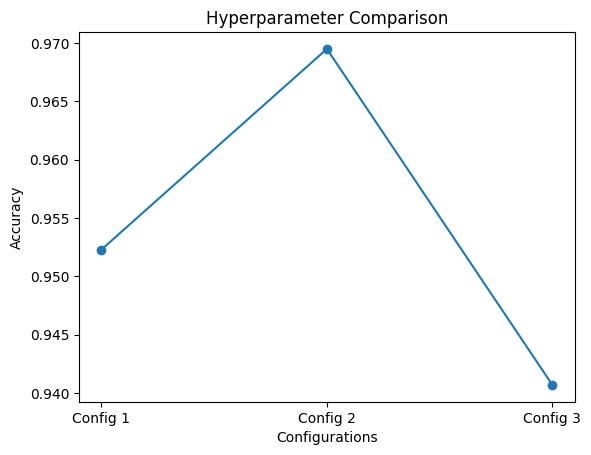

In [32]:
plt.plot(df['Accuracy'], marker='o')
plt.xticks([0, 1, 2], ['Config 1', 'Config 2', 'Config 3'])
plt.xlabel('Configurations')
plt.ylabel('Accuracy')
plt.title('Hyperparameter Comparison')
plt.show()

In [33]:
%load_ext tensorboard
%tensorboard --logdir logs

In [35]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train / 255.0
x_test = x_test / 255.0

In [36]:
# Step II : Load the Data
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']